Factor selection: ridge versus lasso

Reading Material: its is recommended to study Regularization: factors selection.

Code reference, become familiar with the script s_lasso_vs_ridge, that compares the lasso and ridge factor
selection approaches for a regression model in the stock market.

Assume a univariate target process Xt defined as the daily return f the S&P 500 index,
the factors Zt = (Z1t,Z2t)' defined as the linear returns of k_bar = 2 stocks in the S&P500
and the respective daily observations.
Also consider exponential flexible probabilities {Pt|T_HL}t_bar, t=1 with half life parameter THL = 5.


Prepare environment

In [1]:
from numpy import arange, array, average, c_, cov, diff, exp, linspace, log, sum, sqrt, zeros
from numpy.linalg import inv
from sklearn.linear_model import Lasso, Ridge
from pandas import merge, read_csv, to_datetime
from seaborn import lineplot
from matplotlib.pyplot import show, ticklabel_format

In [2]:
# Find the ROOT & DATA path
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_DIR = ROOT / "data"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # lets 'from arpym...' work from any subfolder

Load data

- From SPX database, we upload the time series of he prices of the S&P 500 index

In [3]:
#
db_stocks_sp500_spx = read_csv(DATA_DIR /"SPX.csv", parse_dates=['date'], date_format='mixed', index_col=0)

From db_stocks_sp database, w euload the time series of the stock prices.

We then merge the datasets, and get the traget process using the S&P500 index and the factors using
the stocks CSCO and GE.

In [4]:
db_stocks_sp = read_csv(DATA_DIR /'db_stocks_sp.csv',
                        skiprows=[0], parse_dates=['date'])

# convert 'date' column to datetime type
db_stocks_sp['date'] = to_datetime(db_stocks_sp['date'], format='%d-%b-%y')
# merge databases based on dates
spx_stocks = merge(db_stocks_sp500_spx, db_stocks_sp, on='date', how='inner')
# S&P 500 index
v_spx = array(spx_stocks['SPX_close'])
# stocks
v_t_stocks = array(spx_stocks[['CSCO', 'GE']])
# target process
x = diff(v_spx)/v_spx[:-1]
# factors process
z = diff(v_t_stocks, axis=0)/v_t_stocks[:-1, :]

C:\Users\Administrator\AppData\Local\Temp\ipykernel_16764\2834797506.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  spx_stocks = merge(db_stocks_sp500_spx, db_stocks_sp, on='date', how='inner')


Task 1:

Define a set of penalties {gamma ridge} 100, h=1 in the interval [0, 0.0004].
Plot the evolution of the ridge loadings as functions of gamma ridege.

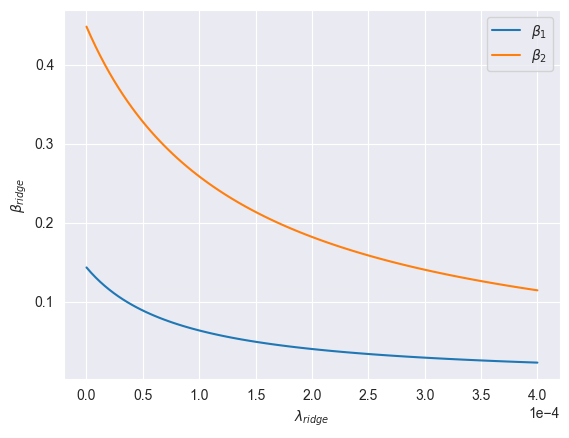

In [6]:
############################# inputs ##############################
# number of factors
k_bar = 2
 # number of target variables
n_bar = 1
# length of penalties grid
l_bar = 100
# maximum value of ridge penalties
lambda_ridge_max = 0.0004
# half-life parameter in flexible probabilities
tau_hl = 5
# target for exponential decay probabilities
t_star = x.shape[0]
###################################################################

# exponential decay probabilities
p = exp(-(log(2)/tau_hl)*abs(t_star - arange(0, t_star)))
# rescaled probabilities
p = p/sum(p)

# data preparation
# mean of targets
m_x = average(x, weights=p)
# standardized targets
x_p = (x - m_x)*sqrt(p)
# mean of factors
m_z = average(z, weights=p, axis=0)
# standardized factors
z_p = (z - m_z)*sqrt(p).reshape(-1, 1)

# ridge regression
# grid of penalties
lambda_grid_ridge = linspace(0, lambda_ridge_max, l_bar)
beta_hat_ridge = zeros((k_bar, l_bar))
for l in range(l_bar):
    # ridge regression model
    clf = Ridge(alpha=lambda_grid_ridge[l], fit_intercept=False)
    # fit ridge regression model
    clf.fit(z_p, x_p)
    # ridge loadings
    beta_hat_ridge[:, l] = clf.coef_


######################################## plot ########################################
# evolution of ridge loadings
[lineplot(x=lambda_grid_ridge, y=beta_hat_ridge.T[:, k], label=f'$\\beta_{k+1}$').set(
          xlabel='$\lambda_{ridge}$', ylabel='$\\beta_{ridge}$') for k in range(k_bar)]
ticklabel_format(style='sci', scilimits=(0, 0), axis='x')
show();

Task 2:

Consider the penalties in Task 1 and set gamma.lasso = gamma_ridge/2 for every h=1,....,100.
Plot the evolution of the lasso loadings as functions of gamma lasso.

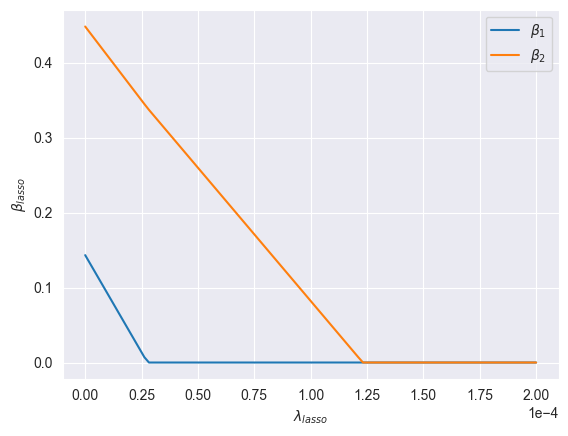

In [7]:
################################# input ##################################
lambda_lasso_max = lambda_ridge_max/2  # maximum value of lasso penalties
##########################################################################

# lasso regression
# grid of penalties
lambda_grid_lasso = linspace(0, lambda_lasso_max, l_bar)
# OLS with flexible probabilities residual covariance
s2_xz_hat_hfp = cov(c_[x, z].T, aweights=p)
beta_hat_lasso = zeros((k_bar, l_bar))
for l in range(l_bar):
    if l==0:
        # OLS loadings
        beta_hat_lasso[:, l] = s2_xz_hat_hfp[0, 1:]@inv(s2_xz_hat_hfp[1:, 1:])
    else:
        # lasso regression model
        clf = Lasso(alpha=lambda_grid_lasso[l]/(2*t_star), fit_intercept=False)
        # fit lasso regression model
        clf.fit(z_p, x_p)
        # lasso loadings
        beta_hat_lasso[:, l] = clf.coef_

######################################### plot #########################################
# evolution of lasso loadings
[lineplot(x=lambda_grid_lasso, y=beta_hat_lasso.T[:, k], label=f'$\\beta_{k+1}$').set(
          xlabel='$\lambda_{lasso}$', ylabel='$\\beta_{lasso}$') for k in range(k_bar)]
ticklabel_format(style='sci', scilimits=(0, 0), axis='x'); show();

Task 3

Consider the results obtained in Task 2 and identify the best factor?

In [8]:
# find the largest penalty with only one non-null column of lasso loadings
index_lambda_ = arange(l_bar)[sum(beta_hat_lasso != 0, axis=0) == 1].max()
lambda_ = lambda_grid_lasso[index_lambda_]

# find the best factor
best_factor = array(['CSCO', 'GE'])[beta_hat_lasso[:, index_lambda_] != 0]